In [1]:
#impor packages
import pandas as pd
import numpy as np
from scipy import stats
from scipy.stats import zscore
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_S=pd.read_csv("../data/sierraleone-bumbuna.csv")
df_S[:2]

,Timestamp,GHI,DNI,DHI,ModA,ModB,Tamb,RH,WS,WSgust,WSstdev,WD,WDstdev,BP,Cleaning,Precipitation,TModA,TModB,Comments
0,2021-10-30 00:01,-0.7,-0.1,-0.8,0.0,0.0,21.9,99.1,0.0,0.0,0.0,0.0,0.0,1002,0,0.0,22.3,22.6,NaN
1,2021-10-30 00:02,-0.7,-0.1,-0.8,0.0,0.0,21.9,99.2,0.0,0.0,0.0,0.0,0.0,1002,0,0.0,22.3,22.6,NaN


In [3]:
# Convert Timestamp to datetime
df_S['Timestamp'] = pd.to_datetime(df_S['Timestamp'], errors='coerce')
df_S.set_index('Timestamp', inplace=True)

In [4]:
df_S.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 525600 entries, 2021-10-30 00:01:00 to 2022-10-30 00:00:00
Data columns (total 18 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   GHI            525600 non-null  float64
 1   DNI            525600 non-null  float64
 2   DHI            525600 non-null  float64
 3   ModA           525600 non-null  float64
 4   ModB           525600 non-null  float64
 5   Tamb           525600 non-null  float64
 6   RH             525600 non-null  float64
 7   WS             525600 non-null  float64
 8   WSgust         525600 non-null  float64
 9   WSstdev        525600 non-null  float64
 10  WD             525600 non-null  float64
 11  WDstdev        525600 non-null  float64
 12  BP             525600 non-null  int64  
 13  Cleaning       525600 non-null  int64  
 14  Precipitation  525600 non-null  float64
 15  TModA          525600 non-null  float64
 16  TModB          525600 non-null  float64


In [5]:
df_S.describe()

,GHI,DNI,DHI,ModA,ModB,Tamb,RH,WS,WSgust,WSstdev,WD,WDstdev,BP,Cleaning,Precipitation,TModA,TModB,Comments
count,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,0.0
mean,201.957515,116.376337,113.720571,206.643095,198.114691,26.319394,79.448857,1.146113,1.691606,0.363823,133.044668,7.172220,999.876469,0.000967,0.004806,32.504263,32.593091,NaN
std,298.495150,218.652659,158.946032,300.896893,288.889073,4.398605,20.520775,1.239248,1.617053,0.295000,114.284792,7.535093,2.104419,0.031074,0.047556,12.434899,12.009161,NaN
min,-19.500000,-7.800000,-17.900000,0.000000,0.000000,12.300000,9.900000,0.000000,0.000000,0.000000,0.000000,0.000000,993.000000,0.000000,0.000000,10.700000,11.100000,NaN
25%,-2.800000,-0.300000,-3.800000,0.000000,0.000000,23.100000,68.700000,0.000000,0.000000,0.000000,0.000000,0.000000,999.000000,0.000000,0.000000,23.500000,23.800000,NaN
50%,0.300000,-0.100000,-0.100000,3.600000,3.400000,25.300000,85.400000,0.800000,1.600000,0.400000,161.500000,6.200000,1000.000000,0.000000,0.000000,26.600000,26.900000,NaN
75%,362.400000,107.000000,224.700000,359.500000,345.400000,29.400000,96.700000,2.000000,2.600000,0.600000,234.100000,12.000000,1001.000000,0.000000,0.000000,40.900000,41.300000,NaN
max,1499.000000,946.000000,892.000000,1507.000000,1473.000000,39.900000,100.000000,19.200000,23.900000,4.100000,360.000000,98.400000,1006.000000,1.000000,2.400000,72.800000,70.400000,NaN


In [6]:
df_S.isnull().sum()

GHI                   0
DNI                   0
DHI                   0
ModA                  0
ModB                  0
Tamb                  0
RH                    0
WS                    0
WSgust                0
WSstdev               0
WD                    0
WDstdev               0
BP                    0
Cleaning              0
Precipitation         0
TModA                 0
TModB                 0
Comments         525600
dtype: int64

In [7]:
df_S.drop_duplicates()

,GHI,DNI,DHI,ModA,ModB,Tamb,RH,WS,WSgust,WSstdev,WD,WDstdev,BP,Cleaning,Precipitation,TModA,TModB,Comments
Timestamp,,,,,,,,,,,,,,,,,,
2021-10-30 00:01:00,-0.7,-0.1,-0.8,0.0,0.0,21.9,99.1,0.0,0.0,0.0,0.0,0.0,1002,0,0.0,22.3,22.6,NaN
2021-10-30 00:02:00,-0.7,-0.1,-0.8,0.0,0.0,21.9,99.2,0.0,0.0,0.0,0.0,0.0,1002,0,0.0,22.3,22.6,NaN
2021-10-30 00:04:00,-0.7,0.0,-0.8,0.0,0.0,21.9,99.3,0.0,0.0,0.0,0.0,0.0,1002,0,0.1,22.3,22.6,NaN
2021-10-30 00:05:00,-0.7,-0.1,-0.8,0.0,0.0,21.9,99.3,0.0,0.0,0.0,0.0,0.0,1002,0,0.0,22.3,22.6,NaN
2021-10-30 00:06:00,-0.7,-0.1,-0.8,0.0,0.0,21.9,99.3,0.0,0.0,0.0,0.0,0.0,1002,0,0.0,22.3,22.7,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-10-29 23:56:00,-1.6,-0.1,-2.9,0.0,0.0,24.0,100.0,0.0,0.0,0.0,0.0,0.0,999,0,0.0,24.2,24.5,NaN
2022-10-29 23:57:00,-1.7,-0.1,-3.0,0.0,0.0,24.0,100.0,0.0,0.0,0.0,0.0,0.0,999,0,0.0,24.2,24.5,NaN
2022-10-29 23:58:00,-1.7,-0.1,-3.1,0.0,0.0,24.0,100.0,0.0,0.0,0.0,0.0,0.0,1000,0,0.0,24.1,24.4,NaN


In [8]:
# Missing value report
missing_values = df_S.isna().sum()
print(missing_values[missing_values > 0])


Comments    525600
dtype: int64


In [10]:
# List columns with >5% nulls
threshold = 0.05 * len(df_S)
high_nulls = missing_values[missing_values > threshold]
print("Columns with >5% nulls:", high_nulls.index.tolist())

Columns with >5% nulls: ['Comments']


Outlier Detection & Basic Cleaning

In [9]:
# 2. Outlier Detection & Basic Cleaning
key_cols = ['GHI', 'DNI', 'DHI', 'ModA', 'ModB', 'WS', 'WSgust']
df_z = df_S[key_cols].apply(zscore)
df_S['outlier_flag'] = (np.abs(df_z) > 3).any(axis=1)
print(f"\nNumber of flagged outlier rows: {df_S['outlier_flag'].sum()}")


Number of flagged outlier rows: 16292


In [10]:
country="sierraleone"
# Impute missing values in key columns with median
for col in key_cols + ['Tamb', 'RH', 'WD', 'BP', 'Cleaning', 'Precipitation', 'TModA', 'TModB']:
    if col in df_S.columns:
        df_S[col].fillna(df_S[col].median(), inplace=True)

# Export cleaned DataFrame (outliers flagged, missings imputed)
clean_path = f'data/{country}_clean.csv'
df_S.to_csv(clean_path, index=True)  # Keep index as Timestamp
print(f"\nCleaned data exported to {clean_path}")


Cleaned data exported to data/sierraleone_clean.csv


<Figure size 1200x600 with 0 Axes>

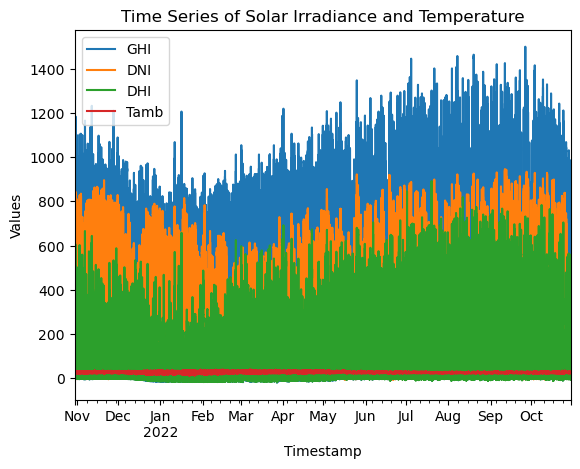

In [11]:
# 3. Time Series Analysis
# Line charts of GHI, DNI, DHI, Tamb vs. Timestamp
plt.figure(figsize=(12, 6))
df_S[['GHI', 'DNI', 'DHI', 'Tamb']].plot()
plt.title('Time Series of Solar Irradiance and Temperature')
plt.xlabel('Timestamp')
plt.ylabel('Values')
plt.show()

<Figure size 1200x600 with 0 Axes>

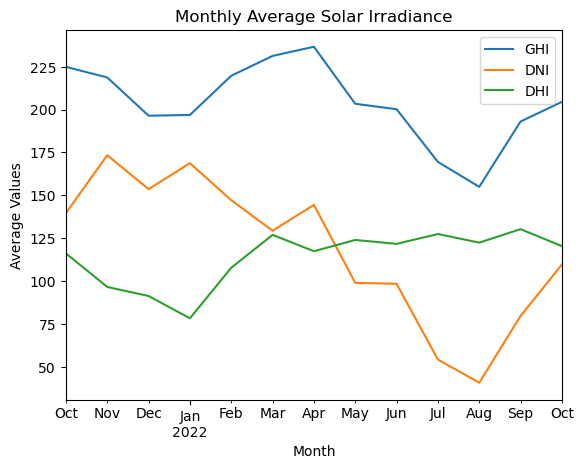

In [12]:
# Monthly patterns
monthly = df_S.resample('M').mean()
plt.figure(figsize=(12, 6))
monthly[['GHI', 'DNI', 'DHI']].plot()
plt.title('Monthly Average Solar Irradiance')
plt.xlabel('Month')
plt.ylabel('Average Values')
plt.show()

<Figure size 1200x600 with 0 Axes>

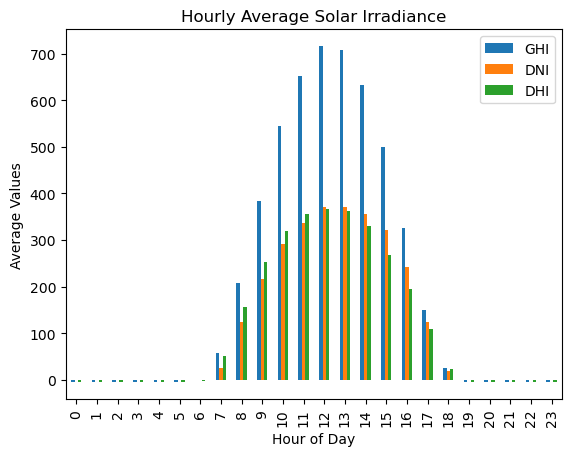

In [13]:
# Daily trends (by hour)
df_S['hour'] = df_S.index.hour
hourly = df_S.groupby('hour').mean()
plt.figure(figsize=(12, 6))
hourly[['GHI', 'DNI', 'DHI']].plot(kind='bar')
plt.title('Hourly Average Solar Irradiance')
plt.xlabel('Hour of Day')
plt.ylabel('Average Values')
plt.show()

<Figure size 800x500 with 0 Axes>

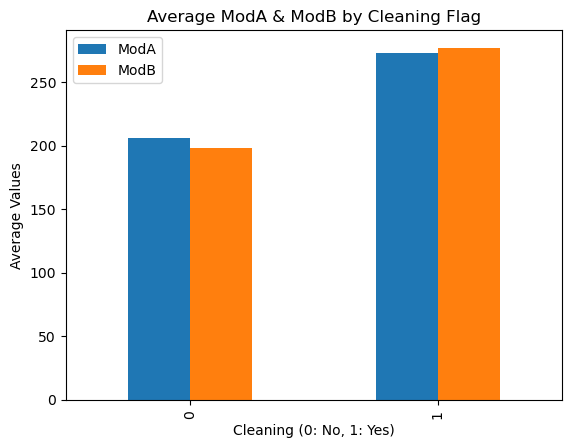

In [14]:
# 4. Cleaning Impact
clean_group = df_S.groupby('Cleaning')[['ModA', 'ModB']].mean()
plt.figure(figsize=(8, 5))
clean_group.plot(kind='bar')
plt.title('Average ModA & ModB by Cleaning Flag')
plt.xlabel('Cleaning (0: No, 1: Yes)')
plt.ylabel('Average Values')
plt.show()

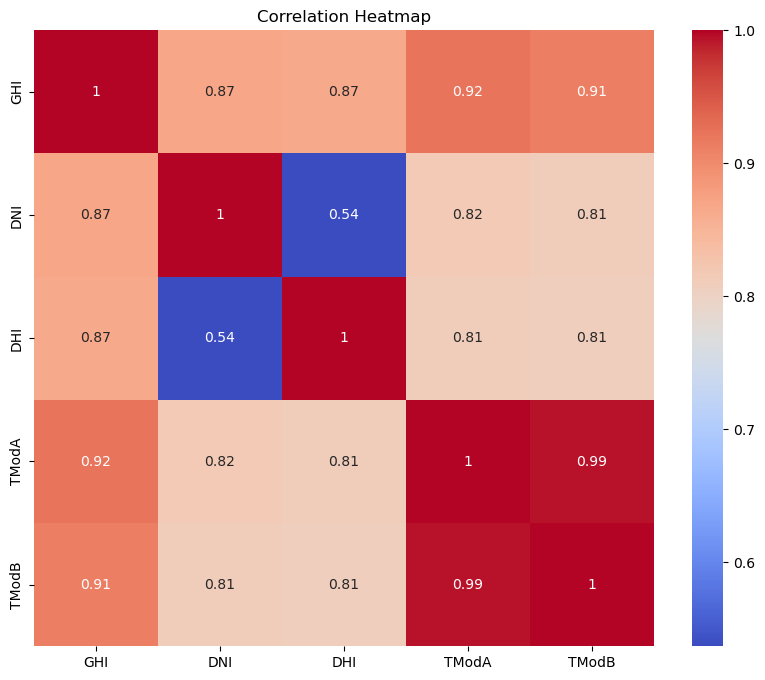

In [17]:
# 5. Correlation & Relationship Analysis
corr_cols = ['GHI', 'DNI', 'DHI', 'TModA', 'TModB']
if all(col in df_S.columns for col in corr_cols):
    corr = df_S[corr_cols].corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, cmap='coolwarm')
    plt.title('Correlation Heatmap')
    plt.show()

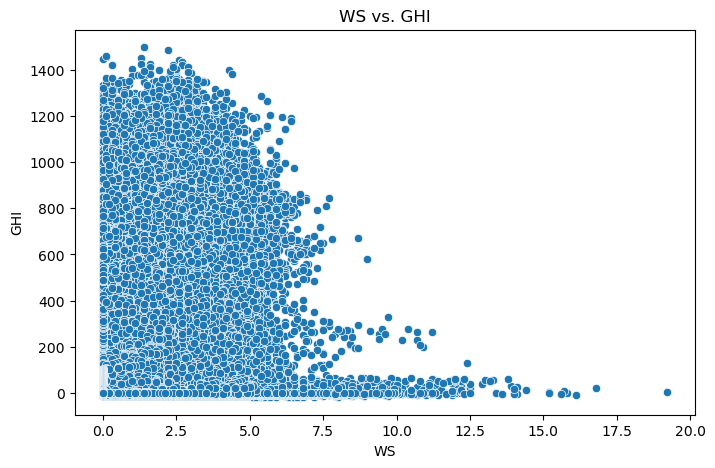

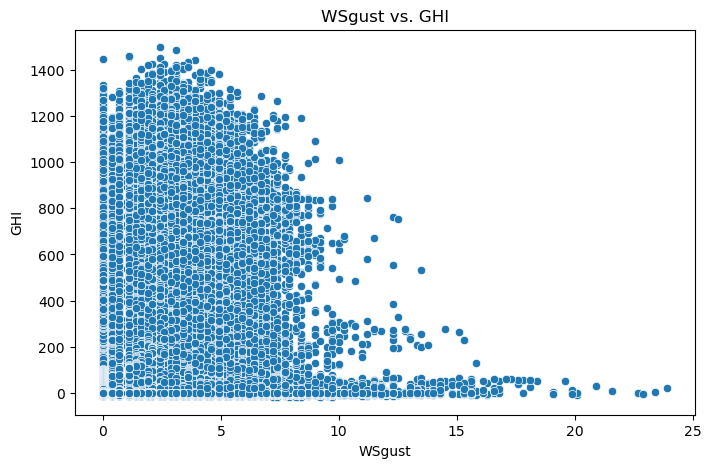

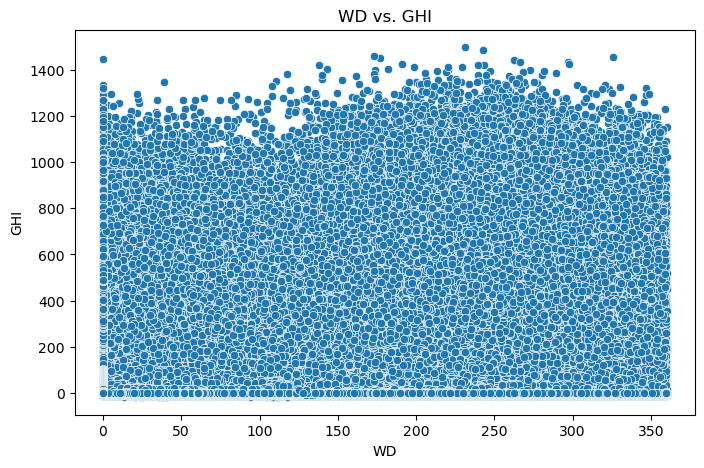

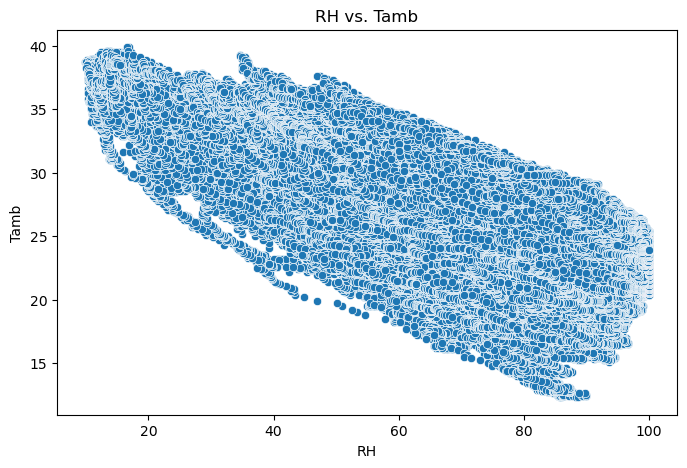

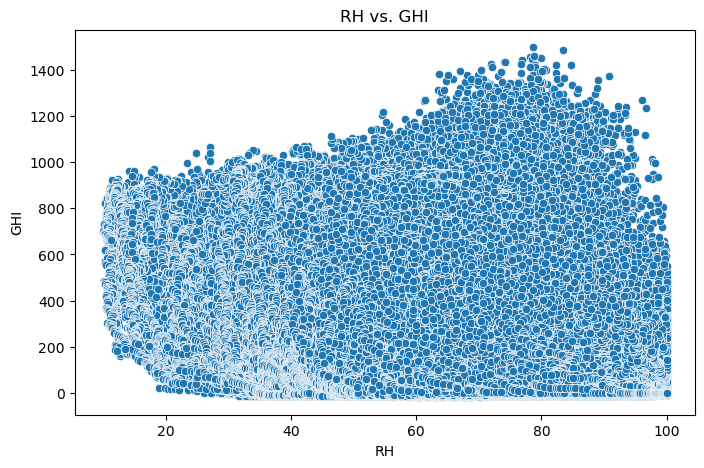

In [18]:
# Scatter plots
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_S, x='WS', y='GHI')
plt.title('WS vs. GHI')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_S, x='WSgust', y='GHI')
plt.title('WSgust vs. GHI')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_S, x='WD', y='GHI')
plt.title('WD vs. GHI')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_S, x='RH', y='Tamb')
plt.title('RH vs. Tamb')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_S, x='RH', y='GHI')
plt.title('RH vs. GHI')
plt.show()

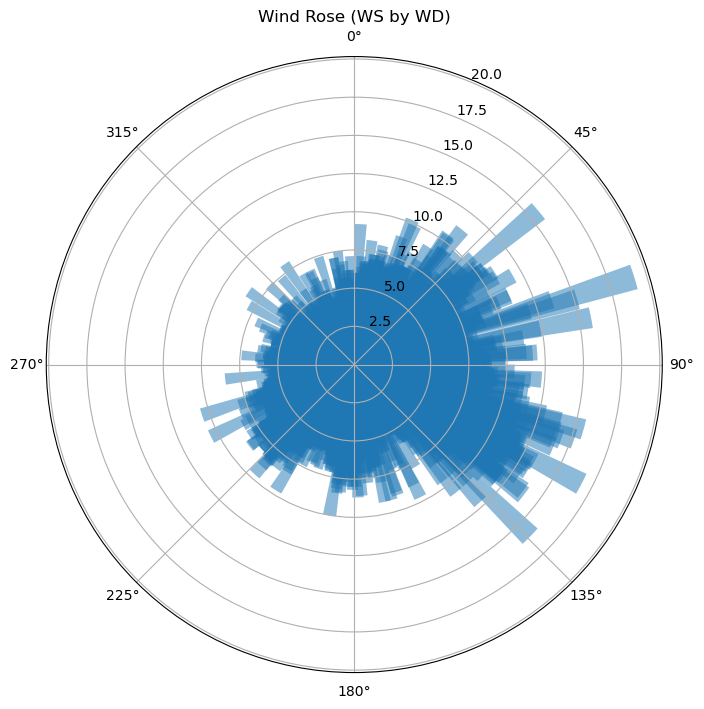

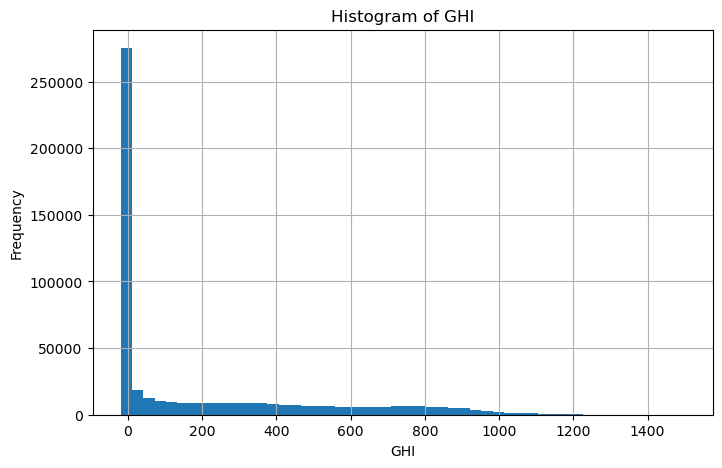

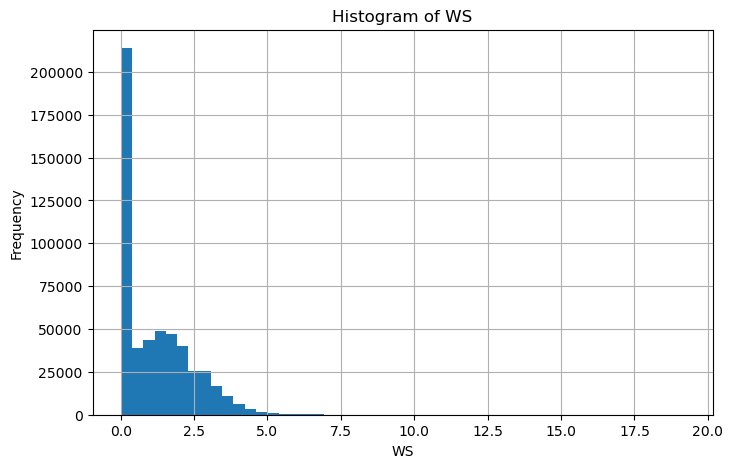

In [15]:
from math import radians
# 6. Wind & Distribution Analysis
# Simple wind rose (polar plot for WD and WS)
plt.figure(figsize=(8, 8))
ax = plt.subplot(111, projection='polar')
ax.bar([radians(w) for w in df_S['WD']], df_S['WS'], width=radians(5), alpha=0.5)
ax.set_theta_direction(-1)
ax.set_theta_zero_location('N')
plt.title('Wind Rose (WS by WD)')
plt.show()

# Histograms
plt.figure(figsize=(8, 5))
df_S['GHI'].hist(bins=50)
plt.title('Histogram of GHI')
plt.xlabel('GHI')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(8, 5))
df_S['WS'].hist(bins=50)
plt.title('Histogram of WS')
plt.xlabel('WS')
plt.ylabel('Frequency')
plt.show()


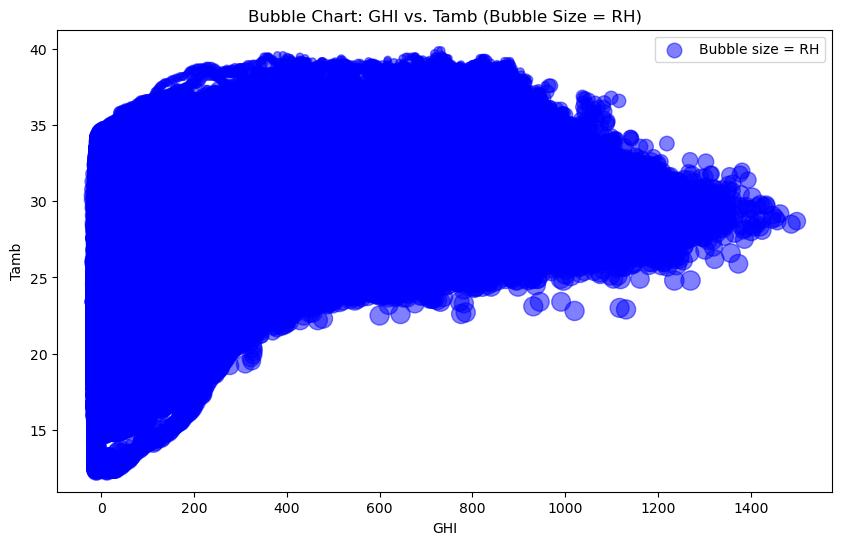

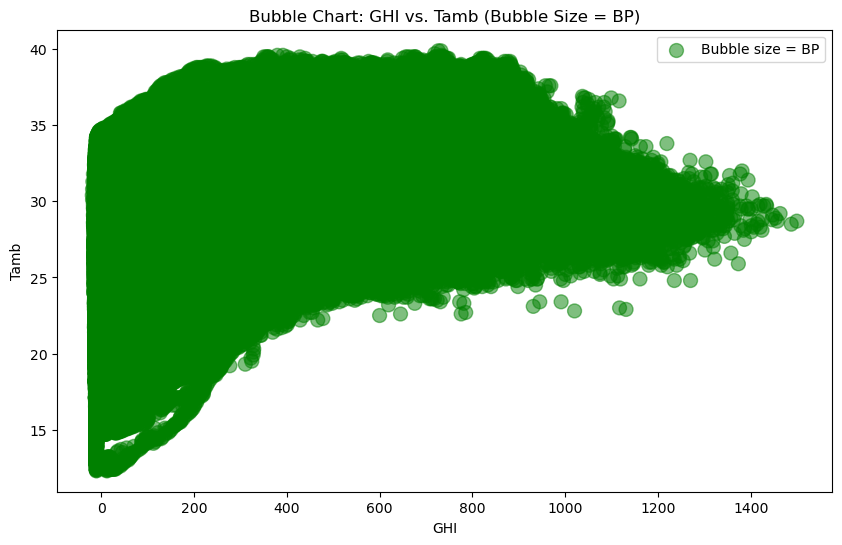

In [16]:
# 7. Temperature Analysis
#  Bubble Chart
plt.figure(figsize=(10, 6))
plt.scatter(df_S['GHI'], df_S['Tamb'], s=df_S['RH'] * 2, alpha=0.5, c='blue', label='Bubble size = RH')  # Scaled size
plt.title('Bubble Chart: GHI vs. Tamb (Bubble Size = RH)')
plt.xlabel('GHI')
plt.ylabel('Tamb')
plt.legend()
plt.show()

# Alternative with BP
plt.figure(figsize=(10, 6))
plt.scatter(df_S['GHI'], df_S['Tamb'], s=df_S['BP'] / 10, alpha=0.5, c='green', label='Bubble size = BP')  # Scaled size
plt.title('Bubble Chart: GHI vs. Tamb (Bubble Size = BP)')
plt.xlabel('GHI')
plt.ylabel('Tamb')
plt.legend()
plt.show()